In [1]:
import torch
import torch.nn.functional as F
from pathlib import Path
import random
import matplotlib.pyplot as plt
import torch.nn as nn
%matplotlib inline

In [2]:
torch.set_default_device("cuda" if torch.cuda.is_available() else "cpu")

In [3]:
path = Path("names.txt")

words = path.read_text().splitlines()

print(len(words))
print(words[:10])

32033
['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia', 'harper', 'evelyn']


In [4]:
chs = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chs)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}
vocab_size = len(itos)

In [24]:
bs = 8

In [25]:
def b_ds(words):
    x, y = [], []
    
    for w in words:
    
        context = [0] * bs
        for ch in w + '.':
            ix = stoi[ch]
            x.append(context)
            y.append(ix)
            context = context[1:] + [ix]
    
    x = torch.tensor(x)
    y = torch.tensor(y)
    return x, y

In [29]:
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

In [30]:
xtrain, ytrain = b_ds(words[:n1])
xval, yval = b_ds(words[n1:n2])
xtest, ytest = b_ds(words[n2:])

In [48]:
class Linear:
  
  def __init__(self, fan_in, fan_out, bias=True):
    self.weight = torch.randn((fan_in, fan_out)) / fan_in**0.5 # note: kaiming init
    self.bias = torch.zeros(fan_out) if bias else None
  
  def __call__(self, x):
    self.out = x @ self.weight
    if self.bias is not None:
      self.out += self.bias
    return self.out
  
  def parameters(self):
    return [self.weight] + ([] if self.bias is None else [self.bias])

class BatchNorm1d:
  
  def __init__(self, dim, eps=1e-5, momentum=0.1):
    self.eps = eps
    self.momentum = momentum
    self.training = True
    self.gamma = torch.ones(dim)
    self.beta = torch.zeros(dim)
    self.running_mean = torch.zeros(dim)
    self.running_var = torch.ones(dim)
  
  def __call__(self, x):
    if self.training:
      if x.ndim == 2:
        dim = 0
      elif x.ndim == 3:
        dim = (0,1)
      xmean = x.mean(dim, keepdim=True) 
      xvar = x.var(dim, keepdim=True)
    else:
      xmean = self.running_mean
      xvar = self.running_var
    xhat = (x - xmean) / torch.sqrt(xvar + self.eps) 
    self.out = self.gamma * xhat + self.beta
    if self.training:
      with torch.no_grad():
        self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * xmean
        self.running_var = (1 - self.momentum) * self.running_var + self.momentum * xvar
    return self.out
  
  def parameters(self):
    return [self.gamma, self.beta]

class Tanh:
  def __call__(self, x):
    self.out = torch.tanh(x)
    return self.out
  def parameters(self):
    return []

class Embedding:
  
  def __init__(self, num_embeddings, embedding_dim):
    self.weight = torch.randn((num_embeddings, embedding_dim))
    
  def __call__(self, IX):
    self.out = self.weight[IX]
    return self.out
  
  def parameters(self):
    return [self.weight]

class FlattenConsecutive:

    def __init__(self, n):
        self.n = n
  
    def __call__(self, x):
        B, T, C = x.shape
        x = x.view(B, T // self.n, C*self.n)
        if x.shape[1] == 1:
            x = x.squeeze(1)
        self.out = x
        return self.out

    def parameters(self):
        return []

class Sequential: 
    
    def __init__(self, layers):
        self.layers = layers

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        self.out = x
        return self.out

    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

In [71]:
model.layers.shape

AttributeError: 'list' object has no attribute 'shape'

In [61]:
# Selected config: {'emb_dim': 24, 'hidden_dim': 750, 'batch_size': 256, 'lr': 0.15355887634905266}, max steps 50_000, 

n_e = 24
n_h = 128


model = Sequential([
    Embedding(vocab_size, n_e),
    FlattenConsecutive(2), Linear(n_e * 2, n_h, bias=False), BatchNorm1d(n_h), Tanh(),
    FlattenConsecutive(2), Linear(n_h * 2, n_h, bias=False), BatchNorm1d(n_h), Tanh(),
    FlattenConsecutive(2), Linear(n_h * 2, n_h, bias=False), BatchNorm1d(n_h), Tanh(),
    Linear(n_h, vocab_size),
])

with torch.no_grad():
    model.layers[-1].weight *= 0.1

parameters = model.parameters()

for p in parameters:
    p.requires_grad = True

In [62]:
max_steps = 200000
batch_size = 32
lossi = []
lr = 0.10

In [63]:
for i in range(max_steps):

    ix = torch.randint(0, xtrain.shape[0], (batch_size,))
    Xb, Yb = xtrain[ix], ytrain[ix] 

    logits = model(Xb)
    loss = F.cross_entropy(logits, Yb)
    
    for p in parameters:
        p.grad = None
    loss.backward()
    
    lr = lr if i < 150000 else lr*0.1 
    for p in parameters:
        p.data += -lr * p.grad
    
    if i % 10000 == 0: 
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())

      0/ 200000: 3.2862
  10000/ 200000: 2.5205
  20000/ 200000: 1.9728
  30000/ 200000: 2.2691
  40000/ 200000: 2.2155
  50000/ 200000: 2.2821
  60000/ 200000: 2.0597
  70000/ 200000: 1.8565
  80000/ 200000: 2.2076
  90000/ 200000: 1.9680
 100000/ 200000: 2.1098
 110000/ 200000: 1.8557
 120000/ 200000: 2.2332
 130000/ 200000: 1.9900
 140000/ 200000: 2.1353
 150000/ 200000: 1.7609
 160000/ 200000: 1.8773
 170000/ 200000: 1.8112
 180000/ 200000: 2.1653
 190000/ 200000: 1.8328


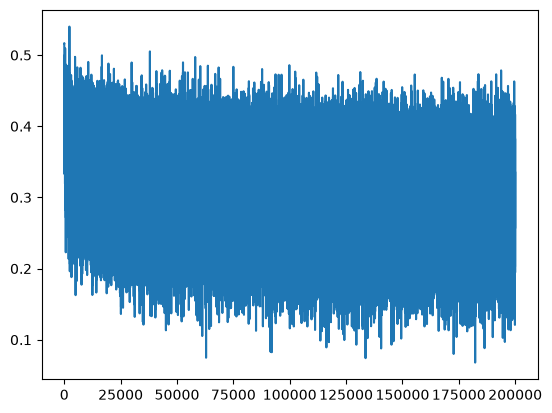

In [64]:
plt.plot(lossi)

In [65]:
for layer in model.layers:
    layer.training = False

In [66]:
@torch.no_grad()

def split_loss(split):
    x, y = {
        'train': (xtrain, ytrain),
        'val': (xval, yval),
        'test': (xtest, ytest),
    }[split]
    logits = model(x)
    loss = F.cross_entropy(logits, y)
    print (split, loss.item())

In [68]:
split_loss('train')
split_loss('val')
split_loss('test')

train 1.9685182571411133
val 2.056419849395752
test 2.0655832290649414


In [60]:
# hyperparam tuning when the nn was much more simple is actually hurting perf now. prior when using optuna to beat Karpathy in lesson 3 I achieved loss 2.05 relative to his 2.17
# using my same hyperparams and adding some complexity to the nn has led to substantial overfitting. train is at ~1.6 now but val / test at ~2.10 so substantial overfitting. now reverting my hyperparams
#post reversion to the karpathy baseline i have now achieved similar loss on val / test as I did by hyperparma tuning with the naive model